# Hawker-centre inspections under uncertain visit durations
**DBA5103 · Extension 3 · West Coast–Jurong West**

## Inputs and workday assumptions

| Input | Source or modelling choice |
|---|---|
| Centre locations, cooked-food stall counts and node IDs | Team’s processed `nodes.csv`. Node 0 is the **Boon Lay Office, 325 Boon Lay Place**, the depot in the processed dataset. Nodes 1–7 are hawker centres. |
| Travel minutes $c_{ij}$ | Team’s `time_matrix_min.csv`, with **row = from** and **column = to**. OSRM estimates are for driving in free-flow conditions. Direction matters. |
| Workday $T$ | One depot-to-depot trip. Travel, service and the return journey count. As agreed with Extensions 1 and 2, we model no separate lunch break or midday closure. We keep free-flow travel fixed to isolate inspection uncertainty. |
| Service times and delays | Scenario assumptions. The dataset contains no measured inspection durations. The values of $b$, $\delta$ and the simulation distribution can be changed. |

In [85]:
from pathlib import Path
from io import StringIO
from itertools import combinations, permutations
from math import factorial, floor, prod

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import gurobipy as gp
    from gurobipy import GRB
except ImportError:
    gp = None

DAY = 480
BASE_SLOPE = 0.5
DELAY_SHARE = 0.30
ALPHAS = tuple(np.round(np.arange(0, 1.01, 0.1), 1))   # level of protection: 0 = none, 1 = full
DRAWS = 10_000
SEED = 5103
SLOPES = tuple(sorted({0.0, BASE_SLOPE, 1.0}))

In [86]:
# Snapshot of the two project inputs used by this model.
NODE_CSV = """node_id,type,short_name,cooked_food_stalls
0,depot,Depot - Town Council (Boon Lay),0
1,hawker,Jurong West Hawker Centre,39
2,hawker,Boon Lay Place Market and Food Village,72
3,hawker,Jurong West Street 52 Blk 505,60
4,hawker,Taman Jurong Market and Food Centre,122
5,hawker,Teban Gardens Market and Food Centre,28
6,hawker,Ayer Rajah Food Centre,80
7,hawker,Clementi West Street 2 Blk 726,60
"""

TRAVEL_CSV = r"""from\to,0,1,2,3,4,5,6,7
0,0.0,4.94,1.61,3.75,4.03,9.52,11.59,12.76
1,5.28,0.0,5.51,5.95,6.69,11.35,13.42,14.33
2,2.66,5.33,0.0,4.56,5.86,11.34,13.42,14.58
3,4.82,6.18,5.54,0.0,5.6,9.53,11.6,12.77
4,4.62,6.08,4.39,5.41,0.0,7.46,9.53,10.44
5,9.41,10.5,9.18,8.72,7.46,0.0,5.29,6.45
6,11.77,12.14,11.54,11.08,9.11,5.81,0.0,3.61
7,12.9,13.28,12.68,12.22,10.24,6.94,3.48,0.0
"""

In [87]:
def read_project_data():
    folders = [Path("data/processed"), Path("../data/processed")]
    for folder in folders:
        node_file = folder / "nodes.csv"
        matrix_file = folder / "time_matrix_min.csv"
        if node_file.exists() or matrix_file.exists():
            return (pd.read_csv(node_file), pd.read_csv(matrix_file, index_col=0),
                    f"Project CSVs in {folder}")
    return (pd.read_csv(StringIO(NODE_CSV)), pd.read_csv(StringIO(TRAVEL_CSV), index_col=0),
            "Embedded copy of the project CSV inputs")


nodes, matrix, source = read_project_data()
nodes = nodes.sort_values("node_id").set_index("node_id")
matrix.index = matrix.index.astype(int)
matrix.columns = matrix.columns.astype(int)
V = tuple(nodes.index)
H = V[1:]
assert V == tuple(range(8)) and nodes.loc[0, "type"] == "depot"
assert matrix.shape == (8, 8) and set(matrix.index) == set(matrix.columns) == set(V)
assert nodes.loc[list(H), "type"].eq("hawker").all()
travel = matrix.loc[list(V), list(V)].to_numpy(dtype=float)
w = nodes.cooked_food_stalls.to_numpy(dtype=float)
assert np.isfinite(travel).all() and (travel >= 0).all() and np.allclose(travel.diagonal(), 0)
assert np.isfinite(w).all() and (w >= 0).all() and np.all(w == np.floor(w)) and w[0] == 0
print(source)
display(nodes[["short_name", "cooked_food_stalls"]].rename(
    columns={"short_name": "Centre / depot", "cooked_food_stalls": "Cooked-food stalls"}))

Project CSVs in ../data/processed


,Centre / depot,Cooked-food stalls
node_id,,
0,Depot - Town Council (Boon Lay),0
1,Jurong West Hawker Centre,39
2,Boon Lay Place Market and Food Village,72
3,Jurong West Street 52 Blk 505,60
4,Taman Jurong Market and Food Centre,122
5,Teban Gardens Market and Food Centre,28
6,Ayer Rajah Food Centre,80
7,Clementi West Street 2 Blk 726,60


In [88]:
results_dir = ((Path("..") if Path.cwd().name == "src" else Path(".")) / "results").resolve()
results_dir.mkdir(parents=True, exist_ok=True)


def save_figure(fig, name):
    fig.savefig(results_dir / f"extension_3_{name}.png", dpi=200, bbox_inches="tight")


BLUE, RED, GREY = "#1f4e79", "#c0504d", "#9aa5b1"
SHADE_NONE, SHADE_ALL = "#f4cccc", "#d9ead3"
TOTAL_STALLS = int(w.sum())


def note_box(ax, text, x=0.02, y=0.97, ha="left", va="top"):
    ax.text(x, y, text, transform=ax.transAxes, ha=ha, va=va,
            bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))


def finish(ax, fig, output_name, legend_loc="lower right"):
    ax.grid(True, alpha=0.25)
    ax.legend(frameon=True, facecolor="white", framealpha=1, loc=legend_loc)
    fig.tight_layout()
    save_figure(fig, output_name)
    plt.show()


def mark_workday(ax):
    ax.axvline(DAY, color="black", linestyle=":", linewidth=1)
    ax.text(DAY - 4, 0.55, f"{DAY} min (8-hour workday)", transform=ax.get_xaxis_transform(),
            fontsize=9, rotation=90, ha="right", va="center")


def time_limit_plot(df, lines, title, ylabel, note, output_name, diagonal=False, shade=True):
    feasible = df["Stalls"].notna()
    x_min, x_max = 0, int(df["Available min"].max())
    first_feasible = int(df.loc[feasible, "Available min"].min())
    all_rows = df["Stalls"].eq(TOTAL_STALLS).fillna(False)
    first_all = int(df.loc[all_rows, "Available min"].min()) if all_rows.any() else None

    fig, ax = plt.subplots(figsize=(10, 5.8))
    if shade:
        ax.axvspan(x_min, first_feasible - 0.5, color=SHADE_NONE, alpha=0.75, label="No stalls visited")
        if first_all is not None:
            ax.axvspan(first_all - 0.5, x_max, color=SHADE_ALL, alpha=0.75, label="All stalls visited")
    for column, colour, label, width in lines:
        ok = df[column].notna()
        ax.plot(df.loc[ok, "Available min"], df.loc[ok, column].astype(float),
                color=colour, linewidth=width, label=label)
    if diagonal:
        ax.plot([x_min, x_max], [x_min, x_max], color="gray", linestyle="--", linewidth=1.5, label="y = x")
    mark_workday(ax)

    ax.set_title(title)
    ax.set_xlabel("Allocated time limit / min")
    ax.set_ylabel(ylabel)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(0, x_max if diagonal else TOTAL_STALLS * 1.15)
    # Mark the first feasible limit and the first all-stalls limit on the x-axis
    extra = {first_feasible} | ({first_all} if first_all is not None else set())
    ticks = [t for t in ax.get_xticks() if all(abs(t - e) >= 20 for e in extra)]
    ax.set_xticks(sorted(set(ticks) | extra))
    ax.set_xticklabels([f"{int(t)}" for t in ax.get_xticks()])
    ax.set_xlim(x_min, x_max)
    note_box(ax, note)
    finish(ax, fig, output_name)


B_STYLES = {0.0: (GREY, "b = 0 (60 min each, Extension 2)", 1.4),
            0.5: (BLUE, "b = 0.5 (baseline): 30 + 0.5w", 2.2),
            1.0: (RED, "b = 1: w", 1.4)}

## 3A · Let larger centres take longer

Among the seven centres, the median stall count is 60. We anchor a 60-stall centre at Extension 2's 60 minutes and let $b$ be the **extra team minutes per additional stall**. For any hawker centre $i$ with $w_i$ stalls,

$$\bar t_i=60+b(w_i-60)=60(1-b)+bw_i,\qquad 0\le b\le1.$$

At $b=0$ each visit takes 60 minutes. At $b=0.5$ we assume 30 minutes of common work plus half a team-minute per stall. At $b=1$ we allow one team-minute per stall. We set both nominal duration and delay allowance to zero at the depot. The 60-stall anchor comes from the data. The slope and fixed component are modelling choices.

**Routing decisions.** Let $V=\{0,\ldots,7\}$, $H=V\setminus\{0\}$ and $A=\{(i,j)\in V^2:i\ne j\}$. Binary $x_{ij}$ selects a road journey, binary $y_i$ selects a visit, and continuous $u_i$ orders the selected centres. We first maximise $\sum_{i\in H}w_i y_i$. Among all coverage-optimal feasible plans, we minimise $C(x)=\sum_{(i,j)\in A}c_{ij}x_{ij}$. This gives a reproducible travel criterion when several plans cover the same number of stalls.

$$
\begin{aligned}
\sum_{j:(i,j)\in A}x_{ij} &= y_i, &
\sum_{j:(j,i)\in A}x_{ji} &= y_i &&(i\in V),\\
y_0 &= 1, & u_0 &= 0,\\
y_i &\le u_i\le 7y_i &&& (i\in H),\\
u_i+1-u_j &\le 8(1-x_{ij}) &&& ((i,j)\in A,\ j\in H),\\
C(x)+\sum_{i\in H}\bar t_i y_i &\le T.&&&
\end{aligned}
$$

Every visited node has one incoming and one outgoing journey. The order increases on selected journeys into a centre, which rules out disconnected cycles. This formulation requires the team to visit at least one centre and return. Section 3B changes only the final time constraint.

In [89]:
def duration_inputs(b, delay_share):
    if not 0 <= b <= 1 or delay_share < 0:
        raise ValueError("Use b between 0 and 1 and a nonnegative delay share.")
    nominal = np.zeros(len(V))
    nominal[1:] = 60 + b * (w[1:] - 60)
    return nominal, delay_share * nominal


nominal, deviations = duration_inputs(BASE_SLOPE, DELAY_SHARE)
inputs = pd.DataFrame({"Centre": nodes.short_name, "Stalls": w.astype(int),
                       "Nominal min": nominal, "Max delay min": deviations,
                       "Upper duration min": nominal + deviations})
display(inputs.round(2))

,Centre,Stalls,Nominal min,Max delay min,Upper duration min
node_id,,,,,
0,Depot - Town Council (Boon Lay),0,0.0,0.00,0.00
1,Jurong West Hawker Centre,39,49.5,14.85,64.35
2,Boon Lay Place Market and Food Village,72,66.0,19.80,85.80
3,Jurong West Street 52 Blk 505,60,60.0,18.00,78.00
4,Taman Jurong Market and Food Centre,122,91.0,27.30,118.30
5,Teban Gardens Market and Food Centre,28,44.0,13.20,57.20
6,Ayer Rajah Food Centre,80,70.0,21.00,91.00
7,Clementi West Street 2 Blk 726,60,60.0,18.00,78.00


### Centre size and inspection time

The three lines compare Extension 2's fixed duration with two size-based rules. The dots mark the stall counts in the project data. Their heights come from the assumed formulas.

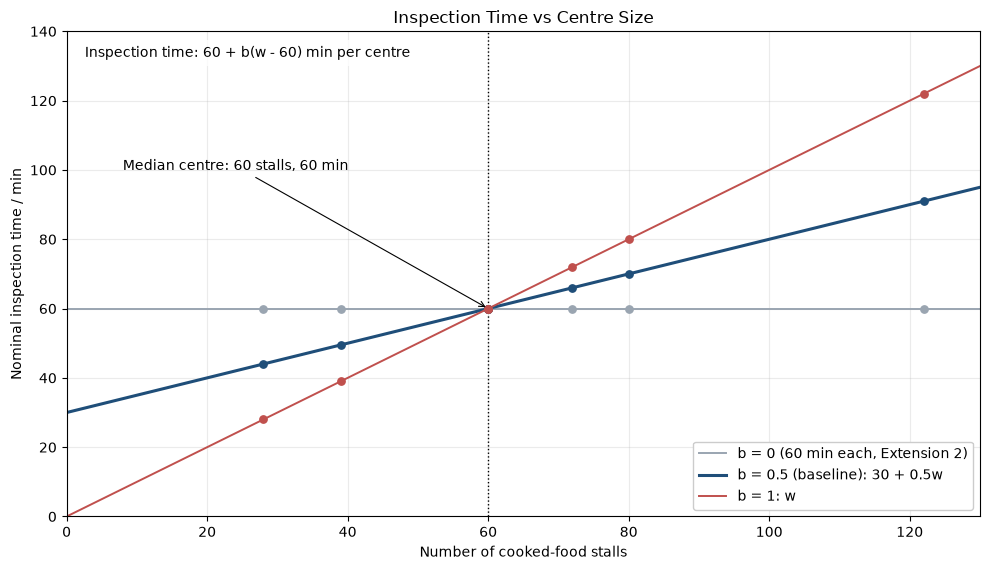

In [90]:
fig, ax = plt.subplots(figsize=(10, 5.8))
sizes = np.linspace(0, max(w) + 8, 200)
for b in SLOPES:
    colour, label, width = B_STYLES[b]
    ax.plot(sizes, 60 + b * (sizes - 60), color=colour, linewidth=width, label=label)
    centre_times, _ = duration_inputs(b, 0.0)
    ax.scatter(w[1:], centre_times[1:], color=colour, s=28, zorder=3)
ax.axvline(60, color="black", linestyle=":", linewidth=1)
ax.annotate("Median centre: 60 stalls, 60 min", xy=(60, 60), xytext=(8, 100),
            arrowprops=dict(arrowstyle="->", lw=0.8))
ax.set_title("Inspection Time vs Centre Size")
ax.set_xlabel("Number of cooked-food stalls")
ax.set_ylabel("Nominal inspection time / min")
ax.set_xlim(0, max(w) + 8)
ax.set_ylim(0, 140)
note_box(ax, "Inspection time: 60 + b(w - 60) min per centre")
ax.legend(frameon=True, facecolor="white", framealpha=1, loc="lower right")
ax.grid(True, alpha=0.25)
fig.tight_layout()
save_figure(fig, "inspection_time")
plt.show()

### How does a longer workday change coverage?

We check every depot-return visiting order and keep the shortest tour for each of the 127 nonempty sets of centres. All orders through a given set have the same service time. This lets us solve each of the 600 whole-minute workday limits from 0 to 599 exactly. Each plan maximises coverage first and minimises driving time second. Blank values identify limits too short for even one visit and a return.

In [91]:
def drive_time(route):
    return float(sum(travel[i, j] for i, j in zip(route, route[1:])))


def build_catalogue():
    catalogue = []
    for size in range(1, len(H) + 1):
        for subset in combinations(H, size):
            tours = ((0, *order, 0) for order in permutations(subset))
            minutes, tour = min((round(drive_time(route), 9), route) for route in tours)
            catalogue.append((subset, tour, minutes, int(w[list(subset)].sum())))
    return catalogue


catalogue = build_catalogue()
print(f"{len(catalogue)} nonempty subsets, "
      f"{sum(factorial(7) // factorial(7 - k) for k in range(1, 8)):,} directed tours checked.")

127 nonempty subsets, 13,699 directed tours checked.


In [92]:
def nominal_sweep(b):
    mu, _ = duration_inputs(b, 0.0)
    options = []
    for subset, route, driving, stalls in catalogue:
        used = driving + mu[list(subset)].sum()
        options.append((stalls, driving, route, used))
    options.sort(key=lambda p: (-p[0], p[1], p[2]))

    rows = []
    for limit in range(600):
        feasible = next((p for p in options if p[3] <= limit + 1e-8), None)
        if feasible is None:
            rows.append((b, limit, np.nan, np.nan, None))
        else:
            stalls, _, route, used = feasible
            rows.append((b, limit, stalls, used, " → ".join(map(str, route))))
    return rows


sweep = pd.DataFrame([row for b in SLOPES for row in nominal_sweep(b)],
                     columns=["b", "Available min", "Stalls", "Time used", "Route"])
sweep["Stalls"] = sweep["Stalls"].astype("Int64")
baseline_sweep = sweep[sweep["b"].eq(BASE_SLOPE)]
display(baseline_sweep[baseline_sweep["Available min"].isin([300, 400, DAY, 500])]
        .drop(columns="b").set_index("Available min").round(2))

minimum_all = sweep[sweep["Stalls"].eq(int(w.sum()))].groupby("b")["Available min"].min()
display(minimum_all.rename("First whole-minute limit covering all seven centres").to_frame())

,Stalls,Time used,Route
Available min,,,
300,293,289.61,0 → 2 → 1 → 3 → 4 → 0
400,394,383.15,0 → 2 → 3 → 7 → 6 → 4 → 0
480,433,439.37,0 → 2 → 1 → 3 → 7 → 6 → 4 → 0
500,461,486.58,0 → 2 → 1 → 3 → 5 → 7 → 6 → 4 → 0


,First whole-minute limit covering all seven centres
b,
0.0,467
0.5,487
1.0,508


#### Maximum Number of Stalls vs Time Limit (Baseline $b = 0.5$)

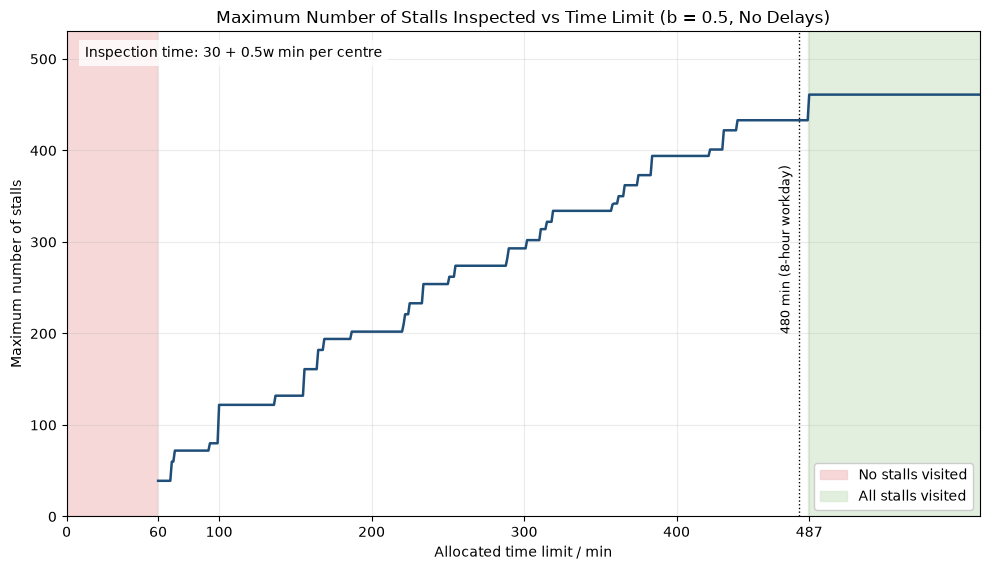

In [93]:
time_limit_plot(
    baseline_sweep, [("Stalls", BLUE, None, 1.8)],
    output_name="nominal_stalls_by_limit",
    title="Maximum Number of Stalls Inspected vs Time Limit (b = 0.5, No Delays)",
    ylabel="Maximum number of stalls",
    note="Inspection time: 30 + 0.5w min per centre",
)

#### Total Time Spent vs Time Limit (Baseline $b = 0.5$)

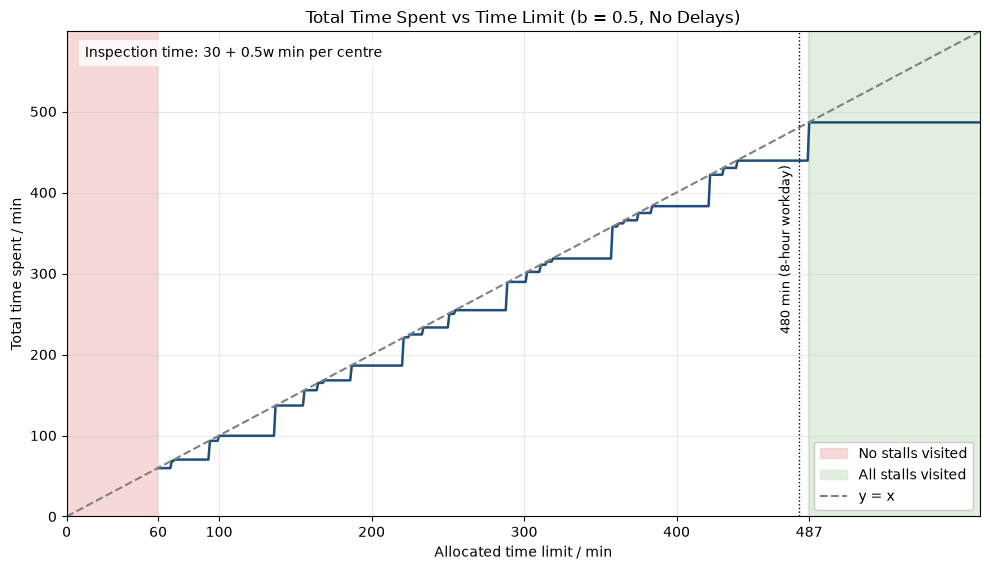

In [94]:
time_limit_plot(
    baseline_sweep, [("Time used", BLUE, None, 1.8)],
    output_name="nominal_time_by_limit",
    title="Total Time Spent vs Time Limit (b = 0.5, No Delays)",
    ylabel="Total time spent / min",
    note="Inspection time: 30 + 0.5w min per centre",
    diagonal=True,
)

#### Comparing Different Values of $b$

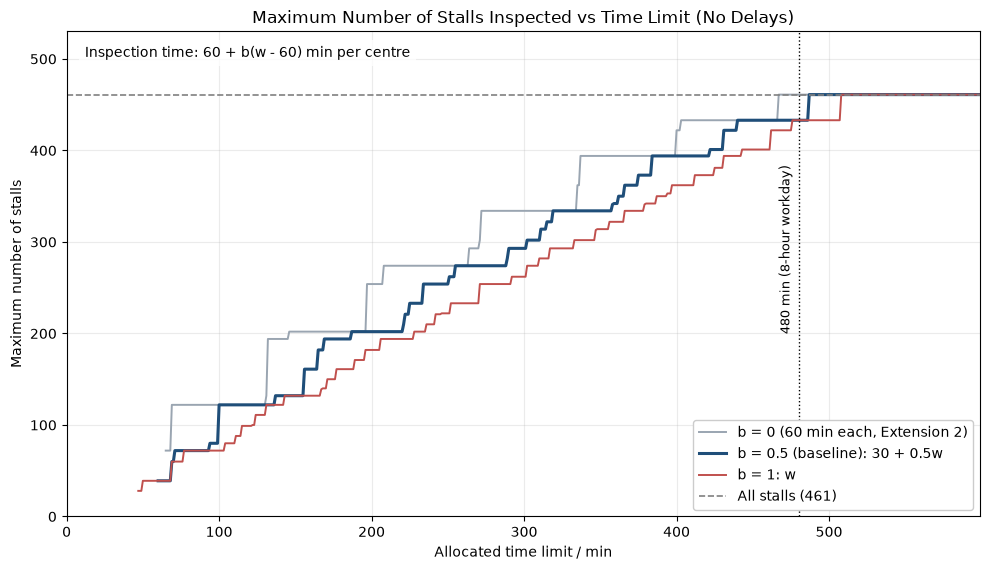

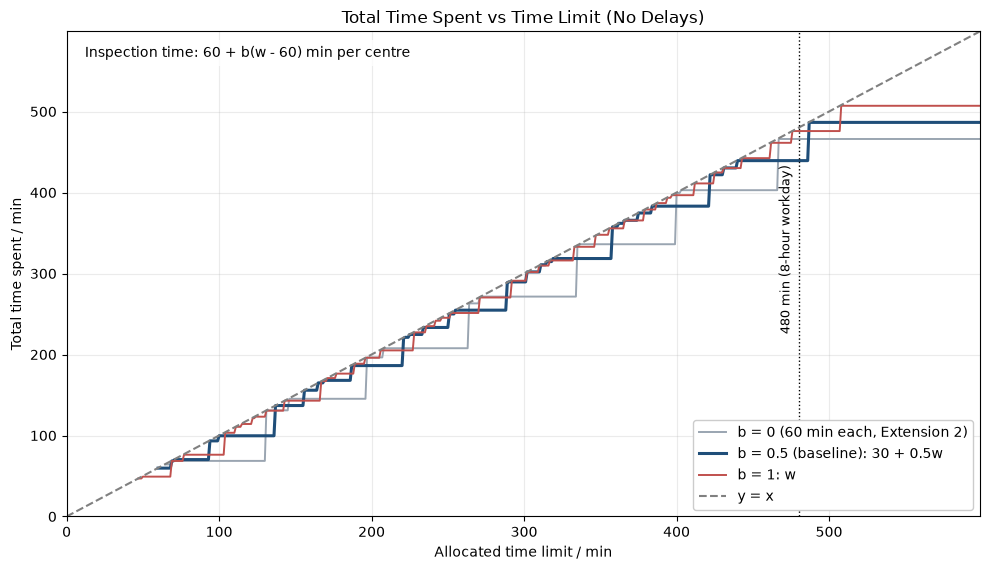

In [95]:
def by_b_plot(column, title, ylabel, diagonal=False):
    fig, ax = plt.subplots(figsize=(10, 5.8))
    for b, group in sweep.groupby("b"):
        colour, label, width = B_STYLES[b]
        ok = group[column].notna()
        ax.plot(group.loc[ok, "Available min"], group.loc[ok, column].astype(float),
                color=colour, linewidth=width, label=label)
    if diagonal:
        ax.plot([0, 599], [0, 599], color="gray", linestyle="--", linewidth=1.5, label="y = x")
    else:
        ax.axhline(TOTAL_STALLS, color="gray", linestyle="--", linewidth=1.2, label=f"All stalls ({TOTAL_STALLS})")
    mark_workday(ax)
    ax.set_title(title)
    ax.set_xlabel("Allocated time limit / min")
    ax.set_ylabel(ylabel)
    ax.set_xlim(0, 599)
    ax.set_ylim(0, 599 if diagonal else TOTAL_STALLS * 1.15)
    note_box(ax, "Inspection time: 60 + b(w - 60) min per centre")
    finish(ax, fig, f"size_sweep_{column.lower().replace(' ', '_')}")


by_b_plot("Stalls", "Maximum Number of Stalls Inspected vs Time Limit (No Delays)", "Maximum number of stalls")
by_b_plot("Time used", "Total Time Spent vs Time Limit (No Delays)", "Total time spent / min", diagonal=True)

With the baseline size rule, the 480-minute day reaches **433 of 461 stalls** across six centres. The shortest tour of all seven needs 46.08 minutes of driving and 440.50 minutes of inspections. Its total is **486.58 minutes**, so **487** is the first whole-minute budget that covers all seven. At 480 minutes, the team omits Teban Gardens (28 stalls) and returns after **439.37 minutes**. Section 3B asks how much of that spare time would be needed if visits ran late.

## 3B · Protect the return time using Lecture 5

The team chooses its route before seeing any delays. We follow the same steps as the Drug M example in Lecture 5 (slides 21–30), with *uncertain inspection times* in place of *uncertain raw-material content*.

### Step 1. Why the 3A plan is risky

The 3A plan returns after **439.37 minutes**, leaving 40.63 minutes spare. If Taman Jurong (up to 27.30 minutes late) and Ayer Rajah (up to 21.00 minutes late) both run late, the day already takes $439.37+27.30+21.00=487.67$ minutes, past the 480-minute limit. If all six visits run late, it takes 558.32 minutes. As with the nominal Drug M plan, a plan that fills the day exactly has no room for anything to go wrong.

### Step 2. Delay model

Let the actual service time be $\tilde t_i=\bar t_i+d_i z_i$ with $0\le z_i\le1$:

- $\bar t_i$ is the nominal time from 3A.
- $d_i=\delta\,\bar t_i$ is the largest possible delay, with baseline $\delta=0.30$: a visit can take up to 30% longer than planned. Larger centres therefore also have larger possible delays.
- $z_i$ is the share of that delay that actually happens: $z_i=0$ means on time and $z_i=1$ means the full delay. Only late finishes use up workday capacity, so unlike Lecture 5, $z_i$ is nonnegative.

**Why 30%?** The dataset contains no recorded inspection durations, so the delay size is an illustrative assumption. A 60-minute visit may take up to 78 minutes, which allows, for example, documenting one or two problems. With a much smaller value the delays would barely matter; with a much larger one, every visit could double in length. Section 3D repeats the analysis with 15% and 45%. The table in 3A lists $\bar t_i$, $d_i$ and the upper duration $\bar t_i+d_i$ for every centre.

### Step 3. How much to protect against: the level of protection $\alpha$

- **No protection** ($\alpha=0$): plan as if nothing runs late. This is 3A.
- **Full protection** ($\alpha=1$): plan as if every selected visit has its full delay. This never runs over, but it is very conservative, because it is unlikely that every visit runs late by the maximum on the same day. (Lecture 5, slide 25, asks the same question about the two raw materials.)
- **Partial protection** ($0<\alpha<1$): limit the **total** amount of delay the route must survive. Lecture 5 limits the two raw-material deviations by $|z_1|+|z_2|\le2\alpha$. With seven centres, the uncertainty set is

$$\mathcal U(\alpha)=\left\{z:0\le z_i\le1,\;\sum_{i\in H}z_i\le7\alpha\right\},\qquad 0\le\alpha\le1.$$

$7\alpha$ is the number of **full-delay equivalents** the route must withstand. At $\alpha=0.5$ this is 3.5: the route must survive any combination of delays adding up to 3.5 full delays, such as three centres fully late and a fourth half late, or all seven half late. Choosing $\alpha$ specifies the scenarios the route must withstand; it is not a probability. A probability estimate requires a separate assumption, introduced in 3C.

| Lecture 5 (Drug M) | Extension 3B |
|---|---|
| Content of raw materials 1 and 2 is uncertain | Inspection time at each centre is uncertain |
| Ingredient constraint: M supplied $\ge 0.5x$ | Time constraint: total time $\le T$ |
| $\lvert z_1\rvert+\lvert z_2\rvert\le2\alpha$ | $\sum_i z_i\le7\alpha$ |
| $\alpha=0$: nominal; $\alpha=1$: full robust | Same |
| Dual of the inner problem gives a linear constraint; the model stays an LP | Same; the model stays a MILP |

### Step 4. The robust time constraint and the worst case

The route must fit within $T$ for every delay pattern in $\mathcal U(\alpha)$, i.e. for the worst one:

$$\underbrace{C(x)+\sum_{i\in H}\bar t_i y_i}_{\text{nominal time}}\;+\;\underbrace{\max_{z\in\mathcal U(\alpha)}\sum_{i\in H}d_i y_i z_i}_{\text{delay reserve } R_\alpha(y)}\;\le\;T.$$

For a **given** set of visits, the worst case is easy to find: spend the budget $7\alpha$ on the largest delays first. For the route chosen at $\alpha=0.5$ (centres 2, 3, 4, 6, 7), the delay bounds in decreasing order are 27.30, 21.00, 19.80, 18.00 and 18.00 minutes. With a budget of 3.5, the reserve is

$$27.30+21.00+19.80+0.5\times18.00=77.10\text{ minutes.}$$

### Step 5. Why we need duality (Lecture 5, slide 29)

The difficulty is that the model **chooses** the visits $y$ at the same time, and a constraint that contains a "max" is not a linear constraint. For fixed $y$, however, $R_\alpha(y)$ is a small LP in $z$. Give the joint budget a dual variable $\pi\ge0$ and each upper bound $z_i\le1$ a dual variable $\rho_i\ge0$. LP duality gives

$$R_\alpha(y)=\min_{\pi,\rho\ge0}\left\{7\alpha\,\pi+\sum_{i\in H}\rho_i:\ \pi+\rho_i\ge d_i y_i\quad(i\in H)\right\}.$$

The inner LP is feasible and bounded, so by strong duality both have the same optimal value. Instead of "the largest possible delay must fit", we can require that **some** $(\pi,\rho)$ satisfying the dual constraints fits. This replaces the max by ordinary linear constraints.

*Intuition.* $\pi$ is a threshold delay and $\rho_i$ is how much centre $i$'s delay bound exceeds it. In the example above, $\pi=18.00$ and $\rho=(9.30,\,3.00,\,1.80,\,0,\,0)$ for centres 4, 6, 2, 3 and 7, so $7\alpha\pi+\sum_i\rho_i=3.5\times18.00+14.10=77.10$.

### Step 6. Full robust model

Same objective and constraints as 3A, with the time limit replaced by

$$C(x)+\sum_{i\in H}\bar t_i y_i+7\alpha\,\pi+\sum_{i\in H}\rho_i\le T,\qquad
\pi+\rho_i\ge d_i y_i\quad(i\in H),\quad \pi,\rho_i\ge0.$$

Since $\alpha$ is fixed, $7\alpha\pi$ is linear (as $2\alpha p_1$ is in Lecture 5), so the model remains a mixed-integer linear program. With $\alpha=0$ it is exactly the 3A model.

**Tight reserve.** The model only needs *some* feasible $(\pi,\rho)$ within $T$, so the solver may return larger dual values than necessary. When reporting, we therefore compute the reserve directly from the selected visits, as in Step 4: the largest $\lfloor 7\alpha\rfloor$ bounds in full, plus the corresponding fraction of the next largest.

### Solving and checking the model

The two methods below use the same priorities. Gurobi solves the robust mixed-integer formulation. With seven centres we can also check every nonempty subset and visiting order. For a fixed subset, service time and delay allowance stay the same in every order, so we retain its shortest directed depot tour. Enumeration verifies optimal coverage and the travel tie-break for each case.

In [96]:
def tight_reserve(bounds, budget):
    """Worst-case extra time when the delays may add up to `budget` full delays (budget = 7 * alpha)."""
    ordered = sorted(bounds, reverse=True)
    count = min(budget, len(ordered))
    full = floor(count + 1e-9)
    fraction = max(count - full, 0.0)
    return sum(ordered[:full]) + (fraction * ordered[full] if full < len(ordered) else 0.0)


def enumerate_optimum(mu, dev, alpha, limit):
    candidates = []
    for subset, route, minutes, coverage in catalogue:
        selected = list(subset)
        total = minutes + mu[selected].sum() + tight_reserve(dev[selected], len(H) * alpha)
        if total <= limit + 1e-8:
            candidates.append((-coverage, minutes, route))
    return min(candidates)[2] if candidates else None

In [97]:
def mip_route(env, mu, dev, alpha, limit):
    arcs = [(i, j) for i in V for j in V if i != j]
    with gp.Model("robust_hawker_visits", env=env) as model:
        model.Params.MIPGap = 0
        model.Params.MIPGapAbs = 0
        x = model.addVars(arcs, vtype=GRB.BINARY, name="arc")
        y = model.addVars(V, vtype=GRB.BINARY, name="visit")
        u = model.addVars(V, lb=0, name="order")
        pi = model.addVar(lb=0, name="pi")
        rho = model.addVars(H, lb=0, name="rho")

        model.addConstr(y[0] == 1)
        model.addConstr(u[0] == 0)
        for i in V:
            model.addConstr(x.sum(i, "*") == y[i])
            model.addConstr(x.sum("*", i) == y[i])
        for i in H:
            model.addConstr(y[i] <= u[i])
            model.addConstr(u[i] <= len(H) * y[i])
        for i, j in arcs:
            if j != 0:
                model.addConstr(u[i] + 1 - u[j] <= len(V) * (1 - x[i, j]))

        driving = gp.quicksum(travel[i, j] * x[i, j] for i, j in arcs)
        service = gp.quicksum(mu[i] * y[i] for i in H)
        for i in H:
            model.addConstr(pi + rho[i] >= dev[i] * y[i])
        model.addConstr(driving + service + len(H) * alpha * pi + rho.sum() <= limit)   # 7 * alpha * pi

        coverage = gp.quicksum(w[i] * y[i] for i in H)
        model.ModelSense = GRB.MAXIMIZE
        model.setObjectiveN(coverage, 0, priority=2, abstol=0, reltol=0)
        model.setObjectiveN(-driving, 1, priority=1, abstol=0, reltol=0)
        model.optimize()
        if model.Status == GRB.INFEASIBLE:
            return None
        if model.Status != GRB.OPTIMAL:
            raise RuntimeError(f"Gurobi status {model.Status}. Optimality unconfirmed.")

        successor = {i: j for i, j in arcs if x[i, j].X > 0.5}
        selected = {i for i in H if y[i].X > 0.5}
        route = [0]
        for _ in V:
            route.append(successor[route[-1]])
            if route[-1] == 0:
                break
        assert route[-1] == 0 and len(route) == len(selected) + 2
        assert set(route[1:-1]) == selected
        return tuple(route)

In [98]:
env = None
if gp is not None:
    try:
        env = gp.Env(empty=True)
        env.setParam("OutputFlag", 0)
        env.setParam("Threads", 1)
        env.start()
    except gp.GurobiError as error:
        if error.errno != gp.GRB.Error.NO_LICENSE:
            raise
        env.dispose()
        env = None
print("Solver: Gurobi, cross-checked by enumeration." if env is not None
      else "Solver: exact enumeration of all tours.")


def solve_case(b, delay_share, alpha, limit):
    if not 0 <= alpha <= 1:
        raise ValueError("The level of protection alpha must lie between 0 and 1.")
    mu, dev = duration_inputs(b, delay_share)
    route = enumerate_optimum(mu, dev, alpha, limit)
    if env is not None:
        mip = mip_route(env, mu, dev, alpha, limit)
        assert (mip is None) == (route is None)
        if mip is not None:
            assert w[list(mip[1:-1])].sum() == w[list(route[1:-1])].sum()
            assert np.isclose(drive_time(mip), drive_time(route), atol=1e-6, rtol=0)
            route = mip
    if route is None:
        raise ValueError(f"No depot tour fits the selected scenario (T={limit}, α={alpha}).")
    selected = list(route[1:-1])
    driving = drive_time(route)
    service = float(mu[selected].sum())
    reserve = tight_reserve(dev[selected], len(H) * alpha)
    protected = driving + service + reserve
    assert protected <= limit + 1e-6
    return {"b": b, "α": alpha, "Route": " → ".join(map(str, route)), "Stops": len(selected),
            "Stalls": int(w[selected].sum()), "Drive": driving, "Service": service,
            "Nominal": driving + service, "Reserve": reserve, "Protected": protected,
            "All delays": driving + service + dev[selected].sum(), "Selected": selected}

Solver: Gurobi, cross-checked by enumeration.


### Routes at different protection levels

We vary $\alpha$ from 0 to 1 in steps of 0.1. All time columns are minutes. **Nominal** includes driving, visits and the return. **Reserve** is the tight delay reserve at that $\alpha$. **Protected** = nominal + reserve. **All delays** allows every selected visit to reach its upper bound.

In [99]:
cases = pd.DataFrame([solve_case(b, DELAY_SHARE, a, DAY) for b in SLOPES for a in ALPHAS])
base = cases[cases["b"].eq(BASE_SLOPE)].set_index("α").sort_index()
display(base[["Stops", "Stalls", "Drive", "Service", "Nominal", "Reserve", "Protected",
              "All delays", "Route"]].round(2))

# Both models must recover the size-dependent 3A result at zero protection.
zero_delay = cases[cases["α"].eq(0)].set_index("b")
for b in SLOPES:
    match = sweep[sweep["b"].eq(b) & sweep["Available min"].eq(DAY)]
    if not match.empty:
        assert zero_delay.loc[b, "Stalls"] == match.iloc[0]["Stalls"]
        assert np.isclose(zero_delay.loc[b, "Nominal"], match.iloc[0]["Time used"])

,Stops,Stalls,Drive,Service,Nominal,Reserve,Protected,All delays,Route
α,,,,,,,,,
0.0,6,433,42.87,396.5,439.37,0.00,439.37,558.32,0 → 2 → 1 → 3 → 7 → 6 → 4 → 0
0.1,6,433,42.87,396.5,439.37,19.11,458.48,558.32,0 → 2 → 1 → 3 → 7 → 6 → 4 → 0
0.2,6,433,42.87,396.5,439.37,35.70,475.07,558.32,0 → 2 → 1 → 3 → 7 → 6 → 4 → 0
0.3,6,401,41.44,380.5,421.94,50.28,472.22,536.09,0 → 2 → 1 → 3 → 5 → 6 → 4 → 0
0.4,5,394,36.15,347.0,383.15,64.14,447.29,487.25,0 → 2 → 3 → 7 → 6 → 4 → 0
0.5,5,394,36.15,347.0,383.15,77.10,460.25,487.25,0 → 2 → 3 → 7 → 6 → 4 → 0
0.6,5,394,36.15,347.0,383.15,89.70,472.85,487.25,0 → 2 → 3 → 7 → 6 → 4 → 0
0.7,5,373,38.22,336.5,374.72,99.46,474.18,475.67,0 → 2 → 1 → 3 → 6 → 4 → 0
0.8,5,373,38.22,336.5,374.72,100.95,475.67,475.67,0 → 2 → 1 → 3 → 6 → 4 → 0


- **$\alpha\le0.2$:** the six-centre plan (433 stalls) still fits. At $\alpha=0.2$ the budget is $7\times0.2=1.4$, so the reserve is $27.30+0.4\times21.00=35.70$ minutes and the protected time is **475.07 minutes**.
- **$\alpha=0.3$:** the budget is 2.1, so the six-centre plan would need $439.37+27.30+21.00+0.1\times19.80=489.65$ minutes. Re-optimising replaces Clementi West Street 2 (60 stalls) with the smaller Teban Gardens (28 stalls) and gives **401 stalls** at 472.22 minutes.
- **$\alpha=0.4$ to $0.6$:** the same five-centre route covers **394 stalls** (worked example below).
- **$\alpha\ge0.7$:** **373 stalls**. This route fits even if every selected visit reaches its upper bound (475.67 minutes), so more protection changes nothing.

Coverage falls from 433 to 373 stalls (−14%) between nominal planning and full protection: the **price of robustness** (Bertsimas and Sim, 2004).

### Worked example from Lecture 5's protection scale

At $\alpha=0.5$ the team plans for $7\alpha=3.5$ full-delay equivalents across the seven centres. On the selected 394-stall route, the delay bounds in descending order are 27.30, 21.00, 19.80, 18.00 and 18.00 minutes. The **required reserve** is $27.30+21.00+19.80+0.5(18.00)=77.10$ minutes. The **available time above the nominal schedule** is $480-383.15=96.85$ minutes. After providing the required reserve the team still has **19.75 minutes** left.

In [100]:
worked = base.loc[0.5]
example_times = pd.Series({
    "Nominal depot-to-depot time": worked["Nominal"],
    "Available time above nominal": DAY - worked["Nominal"],
    "Required delay reserve": worked["Reserve"],
    "Protected depot-to-depot time": worked["Protected"],
    "Time remaining after protection": DAY - worked["Protected"],
}, name="Minutes")
display(example_times.round(2).to_frame())

,Minutes
Nominal depot-to-depot time,383.15
Available time above nominal,96.85
Required delay reserve,77.10
Protected depot-to-depot time,460.25
Time remaining after protection,19.75


### Varying the Time Limit at Partial Protection ($\alpha = 0.5$)

As in Extension 2 and 3A, we solve the protected model for every time limit from 0 to 599 minutes, here at Lecture 5's partial protection level $\alpha = 0.5$. The second plot shows both the planned time without delays and the planned time including the delay reserve; **the gap between the two lines is the time kept free for delays.**

In [101]:
def robust_sweep(b, delay_share, alpha, limits=range(600)):
    mu, dev = duration_inputs(b, delay_share)
    rows = []
    for limit in limits:
        route = enumerate_optimum(mu, dev, alpha, limit)
        if route is None:
            rows.append((limit, np.nan, np.nan, np.nan, None))
            continue
        selected = list(route[1:-1])
        planned = drive_time(route) + mu[selected].sum()
        rows.append((limit, int(w[selected].sum()), planned, planned + tight_reserve(dev[selected], len(H) * alpha),
                     " → ".join(map(str, route))))
    df = pd.DataFrame(rows, columns=["Available min", "Stalls", "Nominal", "Protected", "Route"])
    df["Stalls"] = df["Stalls"].astype("Int64")
    return df


ALPHA_EXAMPLE = 0.5
robust_example_sweep = robust_sweep(BASE_SLOPE, DELAY_SHARE, ALPHA_EXAMPLE)

# The sweep at 480 minutes must match the worked example above
at_day = robust_example_sweep.set_index("Available min").loc[DAY]
assert at_day["Stalls"] == worked["Stalls"] and np.isclose(at_day["Protected"], worked["Protected"])
display(robust_example_sweep[robust_example_sweep["Available min"].isin([300, 400, DAY, 500])]
        .set_index("Available min").round(2))

,Stalls,Nominal,Protected,Route
Available min,,,,
300,254,233.39,298.49,0 → 2 → 3 → 4 → 0
400,334,318.50,395.60,0 → 2 → 3 → 6 → 4 → 0
480,394,383.15,460.25,0 → 2 → 3 → 7 → 6 → 4 → 0
500,401,421.94,499.04,0 → 2 → 1 → 3 → 5 → 6 → 4 → 0


#### Maximum Number of Stalls vs Time Limit ($\alpha = 0.5$)

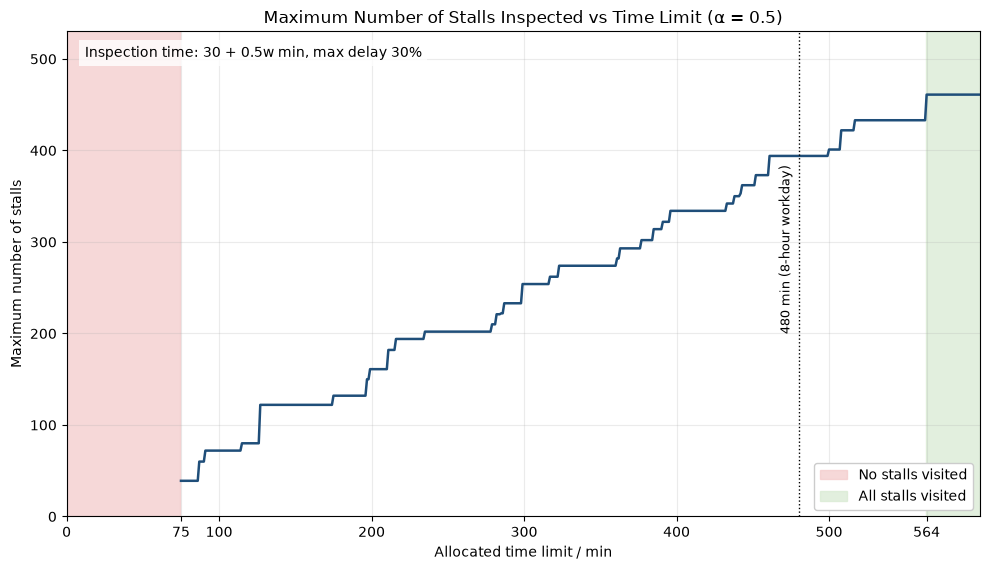

In [102]:
time_limit_plot(
    robust_example_sweep, [("Stalls", BLUE, None, 1.8)],
    output_name="robust_stalls_by_limit",
    title=f"Maximum Number of Stalls Inspected vs Time Limit (α = {ALPHA_EXAMPLE})",
    ylabel="Maximum number of stalls",
    note=f"Inspection time: 30 + 0.5w min, max delay {DELAY_SHARE:.0%}",
)

#### Planned Time vs Time Limit ($\alpha = 0.5$)

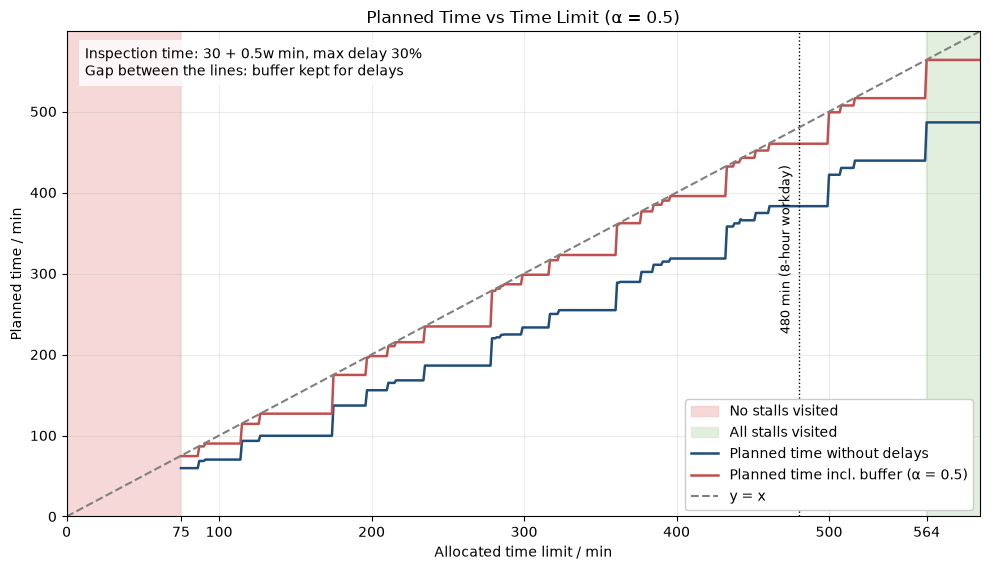

In [103]:
time_limit_plot(
    robust_example_sweep,
    [("Nominal", BLUE, "Planned time without delays", 1.8),
     ("Protected", RED, f"Planned time incl. buffer (α = {ALPHA_EXAMPLE})", 1.8)],
    output_name="robust_time_by_limit",
    title=f"Planned Time vs Time Limit (α = {ALPHA_EXAMPLE})",
    ylabel="Planned time / min",
    note=f"Inspection time: 30 + 0.5w min, max delay {DELAY_SHARE:.0%}\nGap between the lines: buffer kept for delays",
    diagonal=True,
)

#### Comparing Different Levels of Protection Across Time Limits

We repeat the time-limit sweep for $\alpha=0,\ 0.25,\ 0.5,\ 0.75$ and $1$. The second plot shows the planned time without delays: **the gap between each line and $y=x$ is the time the route keeps free for delays**, which grows with $\alpha$.

,First whole-minute limit covering all seven centres
α,
0.00,487.0
0.25,530.0
0.50,564.0
0.75,595.0
1.00,NaN


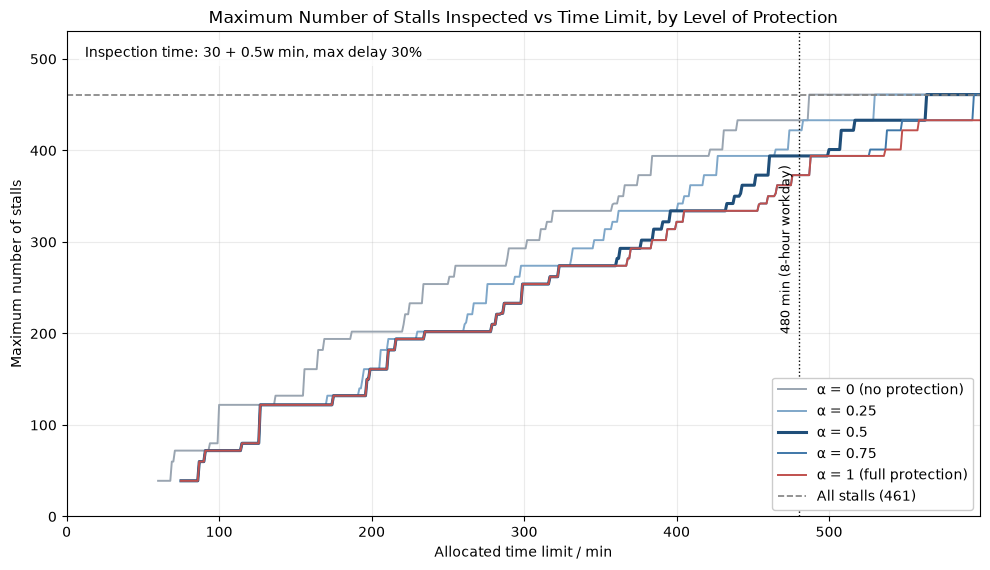

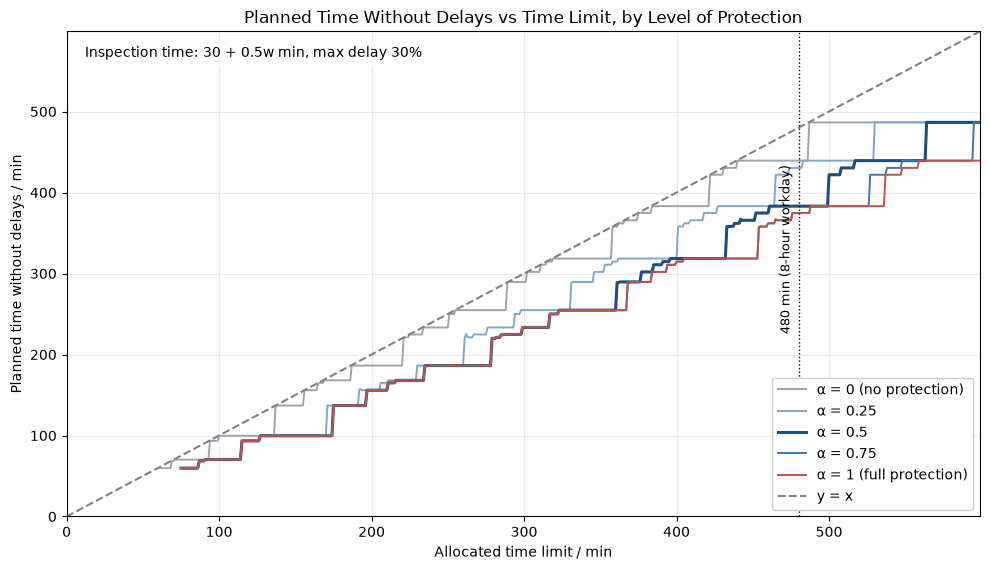

In [107]:
ALPHAS_TO_SWEEP = (0.0, 0.25, 0.5, 0.75, 1.0)
A_STYLES = {0.0: (GREY, "α = 0 (no protection)", 1.4),
            0.25: ("#7fa7c9", "α = 0.25", 1.4),
            0.5: (BLUE, "α = 0.5", 2.2),
            0.75: ("#3f77a8", "α = 0.75", 1.4),
            1.0: (RED, "α = 1 (full protection)", 1.4)}

alpha_sweeps = {a: robust_sweep(BASE_SLOPE, DELAY_SHARE, a) for a in ALPHAS_TO_SWEEP}
display(pd.Series({a: (df.loc[df["Stalls"].eq(TOTAL_STALLS).fillna(False), "Available min"].min()
                       if df["Stalls"].eq(TOTAL_STALLS).fillna(False).any() else np.nan)
                   for a, df in alpha_sweeps.items()},
                  name="First whole-minute limit covering all seven centres").rename_axis("α").to_frame())


def by_alpha_plot(column, title, ylabel, diagonal=False):
    fig, ax = plt.subplots(figsize=(10, 5.8))
    for a, df in alpha_sweeps.items():
        colour, label, width = A_STYLES[a]
        ok = df[column].notna()
        ax.plot(df.loc[ok, "Available min"], df.loc[ok, column].astype(float),
                color=colour, linewidth=width, label=label)
    if diagonal:
        ax.plot([0, 599], [0, 599], color="gray", linestyle="--", linewidth=1.5, label="y = x")
    else:
        ax.axhline(TOTAL_STALLS, color="gray", linestyle="--", linewidth=1.2, label=f"All stalls ({TOTAL_STALLS})")
    mark_workday(ax)
    ax.set_title(title)
    ax.set_xlabel("Allocated time limit / min")
    ax.set_ylabel(ylabel)
    ax.set_xlim(0, 599)
    ax.set_ylim(0, 599 if diagonal else TOTAL_STALLS * 1.15)
    note_box(ax, f"Inspection time: 30 + 0.5w min, max delay {DELAY_SHARE:.0%}")
    finish(ax, fig, f"protection_sweep_{column.lower()}")


by_alpha_plot("Stalls", "Maximum Number of Stalls Inspected vs Time Limit, by Level of Protection",
              "Maximum number of stalls")
by_alpha_plot("Nominal", "Planned Time Without Delays vs Time Limit, by Level of Protection",
              "Planned time without delays / min", diagonal=True)

## 3C · How often does each fixed route run over?

We simulate 10,000 workdays, drawing each centre's delay independently from $\mathrm{Uniform}(0,d_i)$. The team completes its selected route on each day. All routes face the **same simulated workdays**, so identical routes receive identical results. The draws can fall outside $\mathcal U(\Gamma)$, which lets us measure what happens beyond the protected scenarios. Overtime means total duration strictly exceeds 480 minutes.

A simulation may produce zero overruns for a route that can still finish late. We therefore also compute the exact exceedance probability **under the same assumed independent uniforms**. For positive bounds $d_1,\ldots,d_k$, the CDF of their summed delays is
$$ F(s)=\frac{1}{k!\prod_i d_i}\sum_{S\subseteq\{1,\ldots,k\}}(-1)^{|S|}\left(s-\sum_{i\in S}d_i\right)_+^k. $$
The delays' joint uniform density makes this the volume of the box below the time threshold, divided by the box volume. The full-delay upper bound in the results table gives a separate, distribution-free check.

In [104]:
def exact_overtime(bounds, planned, limit):
    widths = [float(d) for d in bounds if d > 0]
    slack = limit - planned
    total = sum(widths)
    if not widths:
        return float(planned > limit)
    if slack <= 0:
        return 1.0
    if slack >= total:
        return 0.0

    # Symmetry lets us evaluate the smaller tail directly for very rare overruns.
    def lower_tail(s):
        k = len(widths)
        volume = 0.0
        for size in range(k + 1):
            for subset in combinations(widths, size):
                volume += (-1)**size * max(s - sum(subset), 0.0)**k
        return volume / (factorial(k) * prod(widths))

    if slack >= total / 2:
        return lower_tail(total - slack)
    return 1.0 - lower_tail(slack)


rng = np.random.default_rng(SEED)
shocks = rng.uniform(size=(DRAWS, len(H)))
risk_rows = []
risk_budgets = sorted(set(GAMMAS).union([round(0.3 * len(H), 8), 0.5 * len(H)]))
for g, plan in base_all.loc[risk_budgets].iterrows():
    ids = np.array(sorted(plan["Selected"]), dtype=int)
    bounds = deviations[ids]
    totals = plan["Nominal"] + shocks[:, ids - 1] @ bounds
    overruns = np.count_nonzero(totals > DAY)
    risk_rows.append({"Γ": g, "Stalls": plan["Stalls"], "Mean actual min": totals.mean(),
                      f"Overruns / {DRAWS:,}": overruns, "Simulated %": 100 * overruns / DRAWS,
                      "Exact %": 100 * exact_overtime(bounds, plan["Nominal"], DAY),
                      "All delays min": plan["All delays"]})
risk = pd.DataFrame(risk_rows).set_index("Γ")
display(risk.round({"Mean actual min": 2, "Simulated %": 2, "Exact %": 5, "All delays min": 2}))

,Stalls,Mean actual min,"Overruns / 10,000",Simulated %,Exact %,All delays min
Γ,,,,,,
0.0,433,498.67,9008,90.08,90.35572,558.32
1.0,433,498.67,9008,90.08,90.35572,558.32
2.0,422,488.82,7254,72.54,73.21836,547.66
2.1,401,478.86,4674,46.74,47.25610,536.09
3.0,394,435.00,0,0.00,0.00454,487.25
3.5,394,435.00,0,0.00,0.00454,487.25
4.0,394,435.00,0,0.00,0.00454,487.25
5.0,373,425.03,0,0.00,0.00000,475.67
6.0,373,425.03,0,0.00,0.00000,475.67


#### Coverage vs Risk of Running Over

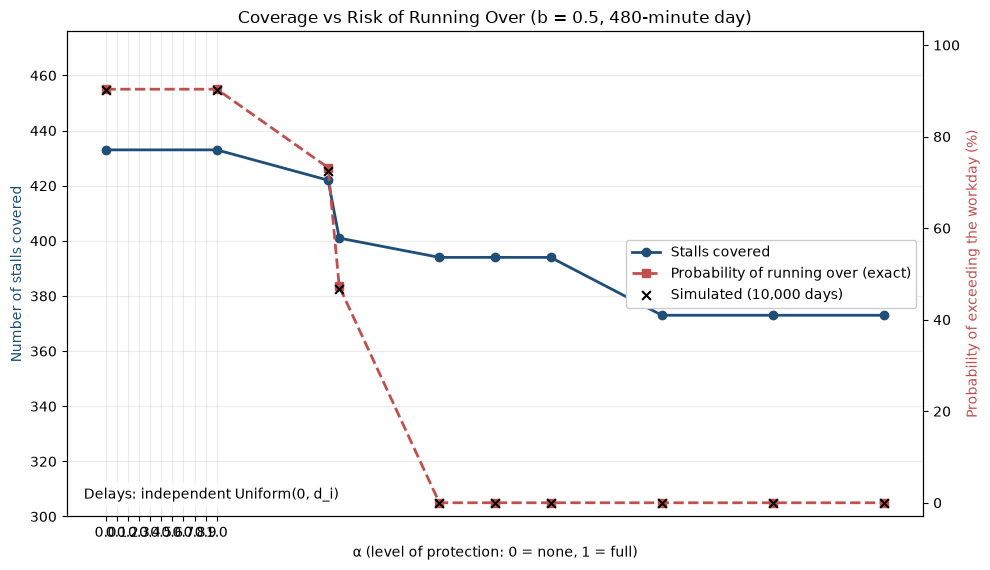

In [108]:
fig, ax1 = plt.subplots(figsize=(10, 5.8))
ax1.plot(risk.index, risk["Stalls"], marker="o", color=BLUE, linewidth=2, label="Stalls covered")
ax1.set_xlabel("α (level of protection: 0 = none, 1 = full)")
ax1.set_ylabel("Number of stalls covered", color=BLUE)
ax1.set_xticks(list(ALPHAS))
ax1.set_ylim(300, TOTAL_STALLS + 15)
ax1.grid(True, alpha=0.25)

ax2 = ax1.twinx()
ax2.plot(risk.index, risk["Exact %"], marker="s", color=RED, linewidth=2, linestyle="--",
         label="Probability of running over (exact)")
ax2.scatter(risk.index, risk["Simulated %"], marker="x", color="black", s=40, zorder=3,
            label=f"Simulated ({DRAWS:,} days)")
ax2.set_ylabel("Probability of exceeding the workday (%)", color=RED)
ax2.set_ylim(-3, 103)

handles = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(handles, labels, frameon=True, facecolor="white", framealpha=1, loc="center right")
ax1.set_title(f"Coverage vs Risk of Running Over (b = {BASE_SLOPE:g}, {DAY}-minute day)")
note_box(ax1, "Delays: independent Uniform(0, d_i)", x=0.02, y=0.03, va="bottom")
fig.tight_layout()
save_figure(fig, "coverage_vs_risk")
plt.show()

Moving from $\alpha=0$ to $\alpha=0.4$ costs **39 stalls (9%)** and reduces the probability of running over from about **90%** to about **0.005%**. Raising $\alpha$ further, to 0.7 or more, costs another 21 stalls and removes the remaining risk entirely under the model.

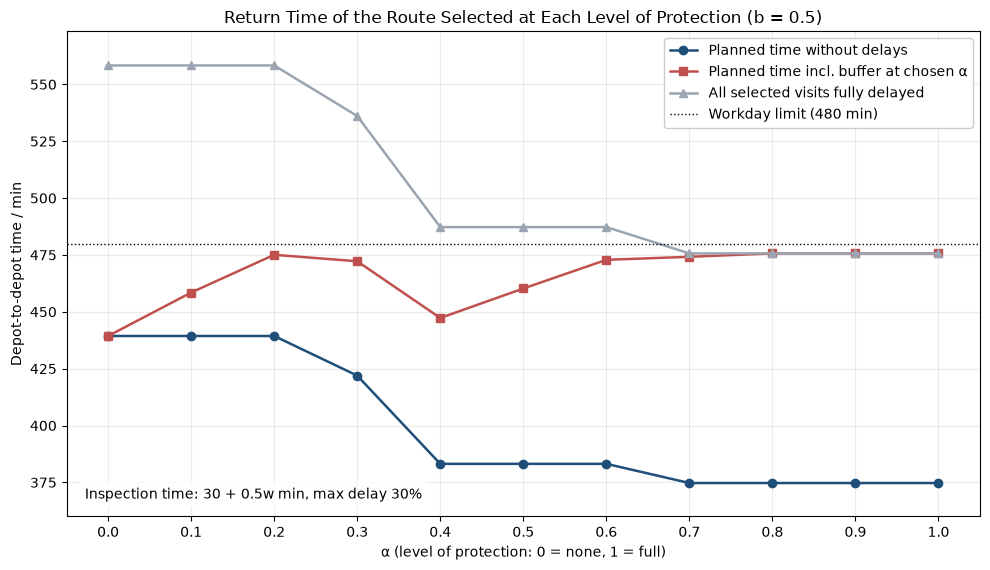

In [109]:
fig, ax = plt.subplots(figsize=(10, 5.8))
for column, colour, marker, label in [("Nominal", BLUE, "o", "Planned time without delays"),
                                      ("Protected", RED, "s", "Planned time incl. buffer at chosen α"),
                                      ("All delays", GREY, "^", "All selected visits fully delayed")]:
    ax.plot(base.index, base[column], marker=marker, color=colour, linewidth=1.8, label=label)
ax.axhline(DAY, color="black", linestyle=":", linewidth=1, label=f"Workday limit ({DAY} min)")
ax.set_title(f"Return Time of the Route Selected at Each Level of Protection (b = {BASE_SLOPE:g})")
ax.set_xlabel("α (level of protection: 0 = none, 1 = full)")
ax.set_ylabel("Depot-to-depot time / min")
ax.set_xticks(list(ALPHAS))
ax.set_ylim(360, base["All delays"].max() + 15)
note_box(ax, f"Inspection time: 30 + 0.5w min, max delay {DELAY_SHARE:.0%}", x=0.02, y=0.03, va="bottom")
finish(ax, fig, "return_time", legend_loc="upper right")

**The 394-stall decision.** $\Gamma=3$ and $\Gamma=4$ select exactly the same route, so the route has the same physical overtime risk under either label. Its all-delay time is **487.25 minutes**. Under the independent uniform assumption, the probability of exceeding 480 minutes is approximately **0.00454%** (about 1 in 22,000 simulated-model days). Positive correlation or a different delay distribution could change that estimate.

**If the return deadline is strict**, the 373-stall route at $\Gamma=5$ fits even when all five selected visits reach their upper bounds. It takes at most **475.67 minutes**, leaving **4.33 minutes** under the model. The choice between these two routes is concrete: covering **21 additional stalls** admits up to **7.25 minutes of overtime**. Both conclusions depend on the assumed service bounds and fixed travel estimates.

## 3D · How much depends on the assumed inspection-time slope?

Keep $T=480$ and $\delta=30\%$ fixed. Each cell gives optimal stall coverage for one size slope and one uncertainty budget. Compare across a row to isolate protection. Compare down a column to see the effect of the size rule. Changing $b$ also changes total nominal service across the seven centres because their average stall count exceeds the 60-stall anchor.

α,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0
b,,,,,,,,,,,
0.0,461,461,433,433,433,433,433,394,394,394,394
0.5,433,433,433,401,394,394,394,373,373,373,373
1.0,433,401,394,373,362,353,342,341,334,334,334


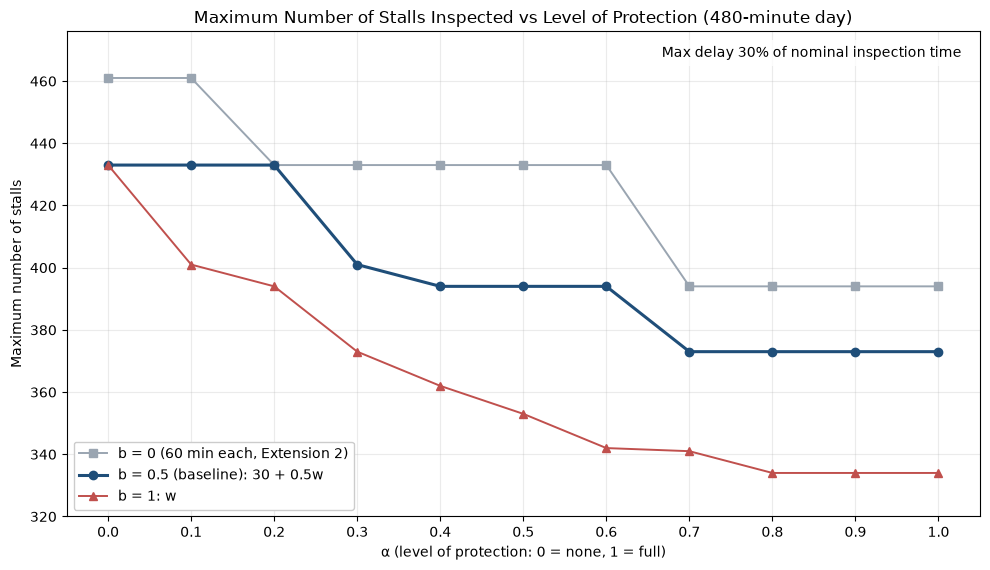

In [110]:
grid = cases.pivot(index="b", columns="α", values="Stalls")
display(grid)
fig, ax = plt.subplots(figsize=(10, 5.8))
markers = {0.0: "s", 0.5: "o", 1.0: "^"}
for b, row in grid.iterrows():
    colour, label, width = B_STYLES[b]
    ax.plot(row.index, row.values, marker=markers[b], color=colour, linewidth=width, label=label)
ax.set_title(f"Maximum Number of Stalls Inspected vs Level of Protection ({DAY}-minute day)")
ax.set_xlabel("α (level of protection: 0 = none, 1 = full)")
ax.set_ylabel("Maximum number of stalls")
ax.set_xticks(list(ALPHAS))
ax.set_ylim(320, TOTAL_STALLS + 15)
note_box(ax, f"Max delay {DELAY_SHARE:.0%} of nominal inspection time", x=0.98, y=0.97, ha="right")
finish(ax, fig, "coverage_sensitivity", legend_loc="lower left")

At $b=0.5$, moving from nominal planning to protection against all delays reduces coverage by **60 stalls** (433 to 373). The same comparison costs **67 stalls** at $b=0$ and **99 stalls** at $b=1$. The one-minute-per-stall case has the largest loss. The three slopes do **not** establish a steadily increasing loss as $b$ rises.

The delay cap is also an assumption. The next table varies it while holding the baseline slope fixed and reports coverage at no protection, intermediate protection and full protection. Inspection start and end times from future field visits could help estimate both the size relationship and a defensible upper delay.

In [111]:
cap_rows = []
for share in (0.15, DELAY_SHARE, 0.45):
    for a in (0, 0.5, 1):
        stalls = (base.loc[a, "Stalls"] if share == DELAY_SHARE
                  else solve_case(BASE_SLOPE, share, a, DAY)["Stalls"])
        cap_rows.append({"Maximum delay": f"{share:.0%} of nominal", "α": a, "Stalls": stalls})
display(pd.DataFrame(cap_rows).pivot(index="Maximum delay", columns="α", values="Stalls"))

α,0.0,0.5,1.0
Maximum delay,,,
15% of nominal,433,433,401
30% of nominal,433,394,373
45% of nominal,433,353,334


## Comparison with Extension 2's 300-minute example

To reproduce Extension 2's example, set $T=300$, $b=0$ and $\alpha=0$. For the earlier guide’s robust comparison only, allow **30 extra minutes per centre** ($\delta=0.5$ of 60). The guide permits inspection times from 30 to 90 minutes. Earlier finishes cannot cause overtime, so its robust upper-time calculation is identical to using just the adverse half of that interval. We keep this scenario separate from the main eight-hour case, which changes both the time limit and the service assumptions.

In [112]:
short_day = pd.DataFrame([solve_case(0, 0.5, a, 300) for a in (0, 0.1, 0.2, 0.3, 0.5, 1)])
display(short_day[["α", "Stops", "Stalls", "Nominal", "Reserve", "Protected", "Route"]]
        .set_index("α").round(2))

,Stops,Stalls,Nominal,Reserve,Protected,Route
α,,,,,,
0.0,4,334,271.50,0.0,271.50,0 → 2 → 3 → 6 → 4 → 0
0.1,4,334,271.50,21.0,292.50,0 → 2 → 3 → 6 → 4 → 0
0.2,3,274,207.75,42.0,249.75,0 → 6 → 4 → 2 → 0
0.3,3,274,207.75,63.0,270.75,0 → 6 → 4 → 2 → 0
0.5,3,274,207.75,90.0,297.75,0 → 6 → 4 → 2 → 0
1.0,3,274,207.75,90.0,297.75,0 → 6 → 4 → 2 → 0


The zero-delay model recovers Extension 2's **334 stalls** at 300 minutes. Extension 2 reports one 292.60-minute route. Our shortest equal-coverage route takes 271.50 minutes, and both plans attain the same primary objective.

Under this guide scenario each full delay adds 30 minutes. At $\alpha=0.1$ the budget is $7\times0.1=0.7$ full delays (21 minutes), so the 334-stall route still fits at **292.50 minutes**. At $\alpha=0.2$ the budget is 1.4 full delays (42 minutes), which would take that route to 313.50 minutes. Re-optimising selects a three-centre, **274-stall** plan, which stays optimal up to full protection (**297.75 minutes**). This matched comparison shows what changes when delay protection is introduced at the original time limit.

## Decision and scope

For the eight-hour day, the team can select the **394-stall route** if a possible 7.25-minute overrun is acceptable under the stated bounds. The route runs from the Boon Lay depot to Boon Lay Place, Jurong West Street 52, Clementi West Street 2, Ayer Rajah and Taman Jurong, then returns to the depot. The **373-stall route** is the highest-coverage choice when the team must finish within the modelled deadline even if every visit takes its maximum time.

These are plans for seven centres under free-flow travel and illustrative inspection times. The project data support the locations, stall counts and driving estimates. Paired observations of actual travel and service durations, especially on days when delays occur at several centres together, would give the team a way to test whether either policy meets its real operating needs.


In [113]:
sweep.to_csv(results_dir / "extension_3_workday_sweep.csv", index=False)
pd.concat(alpha_sweeps, names=["α", "row"]).droplevel("row").to_csv(
    results_dir / "extension_3_robust_workday_sweep.csv"
)
base.drop(columns="Selected").to_csv(results_dir / "extension_3_summary.csv")
risk.to_csv(results_dir / "extension_3_simulation.csv")
cases[["b", "α", "Stalls"]].to_csv(results_dir / "extension_3_size_sensitivity.csv", index=False)
pd.DataFrame(cap_rows).to_csv(results_dir / "extension_3_delay_sensitivity.csv", index=False)
short_day.drop(columns="Selected").to_csv(results_dir / "extension_3_300min_comparison.csv", index=False)
print(f"Results folder: {results_dir}")

Results folder: /Users/piggyzhu/Documents/Master Files/DBA5103/Term Paper/DBA5103-Hawker-Inspection/results
